<p align="center">
    <img src="https://beyondeducation.es/wp-content/uploads/2024/02/CUNEF-UNI50.png" width="500">
</p>


<h1 align="center">Initial Assignment - Machine Learning [P375]</h1>
<h2 align="center">M2026-27 - Máster of Ciencia de Datos e Inteligencia Artificial (MCDIA-3)</h2>
<h3 align="left"><b>Members:</b> Melanie Álvarez, María Victoria del Campo, Alicia Plaza</h3>

<!-- #  <font color=orange> Initial Assignment - Machine Learning [P375]</font>
## M2026-27 - Máster of Ciencia de Datos e Inteligencia Artificial (MCDIA-3) 
### **Members:** Melanie Álvarez, María Victoria del Campo, Alicia Plaza -->

## **Data loading**

In [1]:
import pandas as pd
from pathlib import Path

# Define data directory
DATA_PATH = Path("./data")

# Load datasets
bacteria_dataset = pd.read_csv(DATA_PATH / "Bacteria_dataset_Multiresictance.csv")
print("All datasets loaded successfully!")

All datasets loaded successfully!


## **Data description and inspection**

In [2]:
bacteria_dataset.shape

(10710, 27)

In [3]:
bacteria_dataset.head()

,ID,Name,Email,Address,age/gender,Souches,Diabetes,Hypertension,Hospital_before,Infection_Freq,...,AN,Acide nalidixique,ofx,CIP,C,Co-trimoxazole,Furanes,colistine,Collection_Date,Notes
0,S290,Elizabeth Lawrence,elizabeth.lawrence@example.com,"6350 Robinson Loaf Apt. 447, Paulfurt, RI 30252",37/F,S290 Escherichia coli,No,No,No,0.0,...,S,S,S,S,R,S,S,S,5 Fev 2025,Patient had fever??
1,S291,Tina Sanders,tina.sanders@example.com,"78594 Galloway Port Suite 762, South Tanyatown...",29/F,S291 Morganella morganii,True,No,No,3.0,...,S,S,S,S,S,S,S,S,08/05/2021,تم العلاج
2,S292,Erin Cooke,erin.cooke@example.com,"76661 Isaiah Manors, North Benjamin, HI 85195",77/F,S292 Proteus mirabilis,True,No,No,3.0,...,S,S,S,R,R,S,S,S,01/05/2022,NADA
3,S293,Mrs. Sharon Watson,mrs..sharon.watson@example.com,"1670 Thompson Way Apt. 520, Andrewbury, IL 11534",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-05,PACIENTO ENFERMO
4,S294,Erika Stewart,erika.stewart@example.com,"76838 Patrick Green Suite 538, Torresmouth, ME...",13/F,S294 Escherichia coli,No,Yes,No,1.0,...,R,S,S,S,S,S,S,S,error,NADA


In [4]:
bacteria_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 10710 entries, 0 to 10709
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID                 10710 non-null  str  
 1   Name               10710 non-null  str  
 2   Email              10710 non-null  str  
 3   Address            10710 non-null  str  
 4   age/gender         10089 non-null  str  
 5   Souches            10070 non-null  str  
 6   Diabetes           10075 non-null  str  
 7   Hypertension       10080 non-null  str  
 8   Hospital_before    10073 non-null  str  
 9   Infection_Freq     10071 non-null  str  
 10  AMX/AMP            10052 non-null  str  
 11  AMC                10078 non-null  str  
 12  CZ                 10082 non-null  str  
 13  FOX                10085 non-null  str  
 14  CTX/CRO            10086 non-null  str  
 15  IPM                10077 non-null  str  
 16  GEN                10067 non-null  str  
 17  AN                 1008

In [5]:
# Drop columns containing personal information
bacteria_dataset.drop(columns=['Name', 'Email', 'Address'], inplace=True)

# Check results
bacteria_dataset.head()

/var/folders/w6/tt5g659n54zdxvlqlfd5dy3c0000gn/T/ipykernel_3413/3877739689.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bacteria_dataset.drop(columns=['Name', 'Email', 'Address'], inplace=True)


,ID,age/gender,Souches,Diabetes,Hypertension,Hospital_before,Infection_Freq,AMX/AMP,AMC,CZ,...,AN,Acide nalidixique,ofx,CIP,C,Co-trimoxazole,Furanes,colistine,Collection_Date,Notes
0,S290,37/F,S290 Escherichia coli,No,No,No,0.0,R,R,R,...,S,S,S,S,R,S,S,S,5 Fev 2025,Patient had fever??
1,S291,29/F,S291 Morganella morganii,True,No,No,3.0,S,R,S,...,S,S,S,S,S,S,S,S,08/05/2021,تم العلاج
2,S292,77/F,S292 Proteus mirabilis,True,No,No,3.0,S,R,S,...,S,S,S,R,R,S,S,S,01/05/2022,NADA
3,S293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-05,PACIENTO ENFERMO
4,S294,13/F,S294 Escherichia coli,No,Yes,No,1.0,S,S,R,...,R,S,S,S,S,S,S,S,error,NADA


### *Duplicates*

In [6]:
bacteria_dataset['ID'].nunique()

10710

### *Missing Values*

In [20]:
columna = bacteria_dataset["age/gender"].astype("string")

columna[
    ~columna.str.fullmatch(r"\d+\s*/\s*[FM]", case=False, na=False)
].unique()

<StringArray>
[<NA>, 'missing', '?']
Length: 3, dtype: string

In [21]:
age_gender = bacteria_dataset["age/gender"].astype("string").str.strip()
age_gender = age_gender.mask(
    age_gender.str.lower().isin(["missing", "nan", "?"])
)

bacteria_dataset[["Age", "Gender"]] = age_gender.str.split("/", expand=True)

In [25]:
bacteria_dataset['Age'] = pd.to_numeric(bacteria_dataset['Age'], errors='coerce')

In [26]:
bacteria_dataset.head()

,ID,age/gender,Souches,Diabetes,Hypertension,Hospital_before,Infection_Freq,AMX/AMP,AMC,CZ,...,ofx,CIP,C,Co-trimoxazole,Furanes,colistine,Collection_Date,Notes,Age,Gender
0,S290,37/F,S290 Escherichia coli,0,0,0,0.0,R,R,R,...,S,S,R,S,S,S,5 Fev 2025,Patient had fever??,37,F
1,S291,29/F,S291 Morganella morganii,1,0,0,3.0,S,R,S,...,S,S,S,S,S,S,08/05/2021,تم العلاج,29,F
2,S292,77/F,S292 Proteus mirabilis,1,0,0,3.0,S,R,S,...,S,R,R,S,S,S,01/05/2022,NADA,77,F
3,S293,NaN,NaN,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-05,PACIENTO ENFERMO,<NA>,<NA>
4,S294,13/F,S294 Escherichia coli,0,1,0,1.0,S,S,R,...,S,S,S,S,S,S,error,NADA,13,F


In [27]:
bacteria_dataset["Collection_Date"].unique()

<StringArray>
['5 Fev 2025', '08/05/2021', '01/05/2022', '2020-01-05',      'error',
 '2020-12-31', '05/03/2022', '05/01/2025', '2023-12-31',          nan,
 '3 Jan 1019',          '?', '2024-12-31',    'missing']
Length: 14, dtype: str

In [28]:
bacteria_dataset["collection_year"] = (
    bacteria_dataset["Collection_Date"]
    .astype("string")
    .str.extract(r"(\d{4})", expand=False)
    .astype("Int64")
)

bacteria_dataset = bacteria_dataset.drop(columns="Collection_Date")

In [29]:
bacteria_dataset.head()

,ID,age/gender,Souches,Diabetes,Hypertension,Hospital_before,Infection_Freq,AMX/AMP,AMC,CZ,...,ofx,CIP,C,Co-trimoxazole,Furanes,colistine,Notes,Age,Gender,collection_year
0,S290,37/F,S290 Escherichia coli,0,0,0,0.0,R,R,R,...,S,S,R,S,S,S,Patient had fever??,37,F,2025
1,S291,29/F,S291 Morganella morganii,1,0,0,3.0,S,R,S,...,S,S,S,S,S,S,تم العلاج,29,F,2021
2,S292,77/F,S292 Proteus mirabilis,1,0,0,3.0,S,R,S,...,S,R,R,S,S,S,NADA,77,F,2022
3,S293,NaN,NaN,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,PACIENTO ENFERMO,<NA>,<NA>,2020
4,S294,13/F,S294 Escherichia coli,0,1,0,1.0,S,S,R,...,S,S,S,S,S,S,NADA,13,F,<NA>


Gender               7.124183
Age                  7.124183
Collection_Date      6.246499
AMX/AMP              6.143791
GEN                  6.003735
Souches              5.975724
Co-trimoxazole       5.975724
Infection_Freq       5.966387
Hospital_before      5.947712
Furanes              5.947712
colistine            5.938375
Diabetes             5.929038
IPM                  5.910364
CIP                  5.910364
AMC                  5.901027
Hypertension         5.882353
C                    5.873016
CZ                   5.863679
AN                   5.863679
FOX                  5.835668
CTX/CRO              5.826331
Acide nalidixique    5.807656
age/gender           5.798319
ofx                  5.770308
Notes                1.045752
ID                   0.000000
dtype: float64


<Axes: >

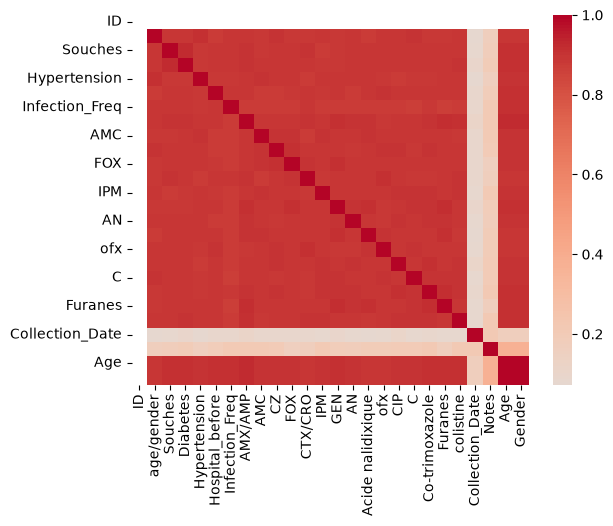

In [11]:
import seaborn as sns
# Percent missing in each column
missing_pct = bacteria_dataset.isna().mean().mul(100).sort_values(ascending=False)
print(missing_pct)

# Whether columns' missing values tend to occur together
missing = bacteria_dataset.isna().astype(int)
missing_corr = missing.corr()

sns.heatmap(missing_corr, cmap="coolwarm", center=0)

In [12]:
mapping = {"true": 1, "yes": 1, "false": 0, "no": 0}

for col in ["Diabetes", "Hypertension", "Hospital_before"]:
    values = bacteria_dataset[col].astype("string").str.strip().str.lower()
    values = values.replace({"?": pd.NA, "missing": pd.NA, "": pd.NA})

    unexpected = set(values.dropna().unique()) - set(mapping)
    if unexpected:
        raise ValueError(f"Valores inesperados en {col}: {unexpected}")

    bacteria_dataset[col] = values.map(mapping).astype("Int64")

In [13]:
bacteria_dataset.head()

,ID,age/gender,Souches,Diabetes,Hypertension,Hospital_before,Infection_Freq,AMX/AMP,AMC,CZ,...,ofx,CIP,C,Co-trimoxazole,Furanes,colistine,Collection_Date,Notes,Age,Gender
0,S290,37/F,S290 Escherichia coli,0,0,0,0.0,R,R,R,...,S,S,R,S,S,S,5 Fev 2025,Patient had fever??,37.0,F
1,S291,29/F,S291 Morganella morganii,1,0,0,3.0,S,R,S,...,S,S,S,S,S,S,08/05/2021,تم العلاج,29.0,F
2,S292,77/F,S292 Proteus mirabilis,1,0,0,3.0,S,R,S,...,S,R,R,S,S,S,01/05/2022,NADA,77.0,F
3,S293,NaN,NaN,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-05,PACIENTO ENFERMO,NaN,NaN
4,S294,13/F,S294 Escherichia coli,0,1,0,1.0,S,S,R,...,S,S,S,S,S,S,error,NADA,13.0,F


In [14]:
pd.crosstab(
    bacteria_dataset["age/gender"].isna(),
    bacteria_dataset["Age"].isna(),
    rownames=["age/gender es NaN"],
    colnames=["Age es NaN"],
    margins=True
)

Age es NaN,False,True,All
age/gender es NaN,,,
False,9947,142,10089
True,0,621,621
All,9947,763,10710


In [17]:
mask = bacteria_dataset["age/gender"].notna() & bacteria_dataset["Age"].isna()

bacteria_dataset.loc[mask, "age/gender"].unique()

<StringArray>
['missing', '?']
Length: 2, dtype: str

Outliers

Correlation

Normalization

Feature Engineering
- Disaggregation
- Categorization

Testing Hypothesis - Insights